# Database composition

The released SSUextract database profiles combine SILVA 138.2 and PR2 5.1.1. The IMG profile adds IMG sequences from eukcensus 2025. This notebook reports source composition, taxonomic resolution, lineage distribution, and available sampling coordinates.

All values are calculated from the released profile manifests and privacy-filtered Parquet tables. `database_composition_provenance.json` records the input and output SHA-256 checksums.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import HTML, SVG, Image, display


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "mkdocs.yml").is_file():
            return candidate
    raise FileNotFoundError("could not locate mkdocs.yml")


def file_sha256(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        while chunk := handle.read(1024 * 1024):
            digest.update(chunk)
    return digest.hexdigest()


def save_figure(figure, stem: str) -> None:
    metadata = {"Date": None, "Creator": "SSUextract"}
    svg = FIGURES / f"{stem}.svg"
    figure.savefig(svg, metadata=metadata)
    svg.write_text(
        "\n".join(line.rstrip() for line in svg.read_text(encoding="utf-8").splitlines()) + "\n",
        encoding="utf-8",
    )
    svg.chmod(0o644)


def compact_count(value: float, _position=None) -> str:
    if value >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    if value >= 1_000:
        return f"{value / 1_000:.0f}k"
    return f"{value:.0f}"


def coverage_label(value: float, suffix: str = "%") -> str:
    precision = 3 if 99.9 < value < 100 else 1
    return f"{value:.{precision}f}{suffix}"


def show_table(frame: pd.DataFrame, formats: dict, uuid: str) -> None:
    style = (
        frame.style.hide(axis="index")
        .set_uuid(uuid)
        .format(formats, na_rep="")
        .set_properties(**{
            "font-family": "Arial, Helvetica, sans-serif",
            "font-size": "12px",
            "color": "#222222",
            "border": "none",
            "padding": "7px 11px",
            "text-align": "right",
        })
        .set_table_styles([
            {
                "selector": "table",
                "props": "border-collapse: collapse; border-top: 1.5px solid #222222; border-bottom: 1.5px solid #222222; margin: 0.5rem 0 1.25rem 0; width: 100%;",
            },
            {
                "selector": "th",
                "props": "font-family: Arial, Helvetica, sans-serif; font-size: 11px; font-weight: 600; color: #222222; background: #f1f1f1; border: none; border-bottom: 1px solid #888888; padding: 8px 11px; text-align: right;",
            },
            {
                "selector": "th:first-child, td:first-child",
                "props": "text-align: left;",
            },
            {
                "selector": "tbody tr:nth-child(even)",
                "props": "background: #f7f7f7;",
            },
        ])
    )
    display(HTML(style.to_html()))


ROOT = find_project_root(Path.cwd().resolve())
DATA = ROOT / "docs" / "data"
FIGURES = ROOT / "docs" / "assets" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "notebooks"))
from beautiful_style import finalize_axes, set_beautiful_style

set_beautiful_style(medium="paper", background="light", dpi=180)
plt.rcParams["svg.hashsalt"] = "ssuextract-database-composition"
plt.ioff()
try:
    from matplotlib_inline.backend_inline import flush_figures
    get_ipython().events.unregister("post_execute", flush_figures)
except (ImportError, ValueError):
    pass


In [2]:
provenance_path = DATA / "database_composition_provenance.json"
provenance = json.loads(provenance_path.read_text(encoding="utf-8"))
assert provenance["schema_version"] == 2

for output in provenance["outputs"]:
    path = ROOT / output["path"]
    assert path.is_file()
    assert path.stat().st_size == output["bytes"]
    assert file_sha256(path) == output["sha256"]

composition = pd.read_csv(DATA / "database_composition.tsv", sep="	", keep_default_na=False)
sources = pd.read_csv(DATA / "database_sources.tsv", sep="	", keep_default_na=False)
resolution = pd.read_csv(DATA / "database_taxonomy_resolution.tsv", sep="	", keep_default_na=False)
lineages = pd.read_csv(DATA / "database_taxonomy_lineages.tsv", sep="	", keep_default_na=False)
connection = duckdb.connect(":memory:")
taxa = connection.execute(
    "SELECT * FROM read_parquet(?)", [str(DATA / "img_taxon_locations.parquet")]
).df()
sites = connection.execute(
    """SELECT * FROM read_parquet(?)
       ORDER BY marker_group, latitude, longitude, taxa, records_16s, records_18s,
                sequences_16s, sequences_18s, taxon_oid_preview""",
    [str(DATA / "img_location_sites.parquet")],
).df()

assert set(composition["profile"]) == {"curated", "img"}
assert composition["count"].ge(0).all()
assert set(sources["source"]) == {
    "SILVA", "PR2", "IMG 16S rRNA genes", "IMG 18S rRNA genes"
}
assert set(resolution["domain"]) == {"Bacteria", "Archaea", "Eukaryota"}
assert set(resolution["target_rank"]) == {"phylum", "supergroup"}
assert (
    resolution["resolved_sequences"] + resolution["unresolved_sequences"]
    == resolution["total_sequences"]
).all()
assert lineages["count"].gt(0).all()
assert taxa["taxon_oid"].is_unique
assert list(taxa.columns) == [
    "taxon_oid", "latitude", "longitude", "records_16s", "records_18s",
    "sequences_16s", "sequences_18s", "marker_group",
]
assert sites[["latitude", "longitude"]].notna().all().all()
assert sites["latitude"].between(-90, 90).all()
assert sites["longitude"].between(-180, 180).all()

coordinate_coverage = provenance["profiles"]["img"]["coordinate_coverage"]
located_taxa = taxa[["latitude", "longitude"]].notna().all(axis=1).sum()
assert len(taxa) == coordinate_coverage["taxa"]
assert located_taxa == coordinate_coverage["located_taxa"]
assert len(sites) == coordinate_coverage["sites"]
assert sites["taxa"].sum() == located_taxa
assert taxa["records_16s"].sum() + taxa["records_18s"].sum() == coordinate_coverage["source_records"]
assert set(sites["marker_group"]) == {"16S + 18S", "16S only", "18S only"}

profile_labels = {"curated": "Curated", "img": "IMG"}
profile_order = ["curated", "img"]
marker_labels = {"16S": "16S rRNA genes", "18S": "18S rRNA genes"}
site_marker_labels = {
    "16S + 18S": "16S rRNA genes and 18S rRNA genes",
    "16S only": "16S rRNA genes only",
    "18S only": "18S rRNA genes only",
}
domain_order = ["Bacteria", "Archaea", "Eukaryota"]
rank_labels = {"phylum": "Phylum", "supergroup": "PR2 supergroup"}


## Released profiles


In [3]:
release_table = pd.DataFrame(
    [
        {
            "Profile": profile_labels[profile],
            "Version": details["version"],
            "Unique sequences": details["counts"]["sequences"],
            "16S rRNA gene membership": details["markers"]["16S"]["sequences"],
            "18S rRNA gene membership": details["markers"]["18S"]["sequences"],
            "Source records": details["counts"]["source_records"],
            "Archive (MiB)": details["archive"]["bytes"] / 1024**2,
        }
        for profile, details in (
            (profile, provenance["profiles"][profile]) for profile in profile_order
        )
    ]
)
show_table(
    release_table,
    {
        "Unique sequences": "{:,.0f}",
        "16S rRNA gene membership": "{:,.0f}",
        "18S rRNA gene membership": "{:,.0f}",
        "Source records": "{:,.0f}",
        "Archive (MiB)": "{:,.1f}",
    },
    "release-profiles",
)


Profile,Version,Unique sequences,16S rRNA gene membership,18S rRNA gene membership,Source records,Archive (MiB)
Curated,1.0.2,"609,298","416,021","193,282","683,597",345.4
IMG,1.0.2,"1,396,949","1,067,340","329,614","1,680,777",840.9


In [4]:
curated_unique = int(provenance["profiles"]["curated"]["counts"]["sequences"])
img_unique = int(provenance["profiles"]["img"]["counts"]["sequences"])
img_source_records_added = int(
    sources.loc[sources["source"].str.startswith("IMG "), "img_source_records"].sum()
)
img_net_new_unique = img_unique - curated_unique
img_collapsed_records = img_source_records_added - img_net_new_unique
exact_sequence_table = pd.DataFrame(
    [
        {
            "Measure": "Additional IMG source records",
            "Count": img_source_records_added,
            "Share of additional IMG records": 100.0,
        },
        {
            "Measure": "Net increase in unique sequences",
            "Count": img_net_new_unique,
            "Share of additional IMG records": img_net_new_unique / img_source_records_added * 100,
        },
        {
            "Measure": "Records not increasing the exact-sequence total",
            "Count": img_collapsed_records,
            "Share of additional IMG records": img_collapsed_records / img_source_records_added * 100,
        },
    ]
)
show_table(
    exact_sequence_table,
    {
        "Count": "{:,.0f}",
        "Share of additional IMG records": "{:.1f}%",
    },
    "exact-sequence-contribution",
)


Measure,Count,Share of additional IMG records
Additional IMG source records,"997,180",100.0%
Net increase in unique sequences,"787,651",79.0%
Records not increasing the exact-sequence total,"209,529",21.0%


The IMG source contributes 997,180 records and increases the profile by 787,651 unique sequences. The remaining 209,529 records are exact duplicates within the IMG contribution or of a SILVA/PR2 reference sequence.


### Source releases

The curated profile contains the SILVA and PR2 reference records. The IMG profile contains the same reference records plus IMG sequences from eukcensus 2025. Exact sequence duplicates are represented once in each profile.


In [5]:
source_table = sources.rename(
    columns={
        "source": "Source",
        "version": "Version",
        "content": "Content",
        "curated_source_records": "Curated records",
        "img_source_records": "IMG records",
        "doi": "DOI",
        "license": "License",
    }
)[
    ["Source", "Version", "Content", "Curated records", "IMG records", "DOI", "License"]
]
show_table(
    source_table,
    {"Curated records": "{:,.0f}", "IMG records": "{:,.0f}"},
    "source-releases",
)


Source,Version,Content,Curated records,IMG records,DOI,License
SILVA,138.2,16S rRNA gene references; bacterial and archaeal taxonomy,"451,555","451,555",10.82364/138.2/SSU/Ref-NR99/FASTA/unaligned,CC-BY-4.0
PR2,5.1.1,18S rRNA gene and organellar 16S rRNA gene references; eukaryotic taxonomy,"232,042","232,042",10.1093/nar/gks1160,MIT
IMG 16S rRNA genes,2025,Additional IMG 16S rRNA gene sequences,0,"839,222",10.5281/zenodo.20653200,CC-BY-4.0
IMG 18S rRNA genes,2025,Additional IMG 18S rRNA gene sequences,0,"157,958",10.5281/zenodo.20653200,CC-BY-4.0


## Taxonomic composition

SILVA supplies bacterial and archaeal taxonomy. PR2 supplies eukaryotic taxonomy, including organellar 16S rRNA gene references. Exact sequences with equally preferred assignments from different domains retain both native alternatives and are reported as ambiguous.


In [6]:
taxonomy_policy_table = pd.DataFrame(
    [
        {
            "Sequence domain": domain,
            "Preferred taxonomy": provenance["taxonomy_policy"][domain],
            "Reported rank": rank_labels[provenance["taxonomy_summary"][domain]["target_rank"]],
            "Source release": (
                f"{provenance['taxonomy_summary'][domain]['taxonomy_source']} "
                f"{provenance['taxonomy_summary'][domain]['taxonomy_source_version']}"
            ),
        }
        for domain in domain_order
    ]
)
show_table(taxonomy_policy_table, {}, "taxonomy-policy")


Sequence domain,Preferred taxonomy,Reported rank,Source release
Bacteria,SILVA 138.2,Phylum,SILVA 138.2
Archaea,SILVA 138.2,Phylum,SILVA 138.2
Eukaryota,PR2 5.1.1,PR2 supergroup,PR2 5.1.1


### Domain assignment

The counts below are absolute unique-sequence assignments. They are not normalized across profiles with different totals or different unclassified fractions. The 1,650 ambiguous assignments are unchanged because the added IMG sequences introduce no new preferred cross-domain conflict. Five exact sequences route to both rRNA gene marker models and are included in both marker-membership totals.


In [7]:
all_domain_order = ["Bacteria", "Archaea", "Eukaryota", "Unclassified", "Ambiguous"]
domains = composition.loc[composition["dimension"].eq("taxonomy_domain")].copy()
domain_matrix = (
    domains.pivot(index="category", columns="profile", values="count")
    .reindex(all_domain_order)
    .fillna(0)
)
domain_table = pd.DataFrame(
    {
        "Assignment": domain_matrix.index,
        "Curated sequences": domain_matrix["curated"].astype(int).to_numpy(),
        "Curated share": (domain_matrix["curated"] / domain_matrix["curated"].sum() * 100).to_numpy(),
        "IMG sequences": domain_matrix["img"].astype(int).to_numpy(),
        "IMG share": (domain_matrix["img"] / domain_matrix["img"].sum() * 100).to_numpy(),
    }
)
show_table(
    domain_table,
    {
        "Curated sequences": "{:,.0f}",
        "Curated share": "{:.1f}%",
        "IMG sequences": "{:,.0f}",
        "IMG share": "{:.1f}%",
    },
    "domain-assignment",
)


Assignment,Curated sequences,Curated share,IMG sequences,IMG share
Bacteria,"388,861",63.8%,"857,491",61.4%
Archaea,"20,182",3.3%,"43,767",3.1%
Eukaryota,"198,605",32.6%,"288,908",20.7%
Unclassified,0,0.0%,"205,133",14.7%
Ambiguous,"1,650",0.3%,"1,650",0.1%


### Resolution to phylum or supergroup

The target rank is phylum for Bacteria and Archaea and PR2 supergroup for Eukaryota. In this release, IMG sequences with a preferred domain assignment stop at domain, while 205,133 sequences remain unclassified at domain. Phylum and supergroup distributions therefore describe the SILVA and PR2 reference component. The resolution statistics below retain domain-only IMG sequences in the relevant domain denominator and exclude unclassified and ambiguous assignments.

Terminal PR2 compartment suffixes (`:apic`, `:chro`, `:chrom`, `:mito`, `:nucl`, and `:plas`) are counted with their parent supergroup. No phylum or supergroup is inferred for a domain-only assignment.


In [8]:
resolution_table = resolution.copy()
resolution_table["Profile"] = resolution_table["profile"].map(profile_labels)
resolution_table["Domain"] = resolution_table["domain"]
resolution_table["Target rank"] = resolution_table["target_rank"].map(rank_labels)
resolution_table = resolution_table.rename(
    columns={
        "total_sequences": "Domain assignments",
        "resolved_sequences": "Resolved to target rank",
        "unresolved_sequences": "Unresolved below domain",
        "resolution_percent": "Resolved (%)",
        "named_lineages": "Named lineages",
    }
)[
    [
        "Domain", "Target rank", "Profile", "Domain assignments",
        "Resolved to target rank", "Unresolved below domain", "Resolved (%)", "Named lineages",
    ]
]
resolution_table["Domain"] = pd.Categorical(
    resolution_table["Domain"], categories=domain_order, ordered=True
)
resolution_table["Profile"] = pd.Categorical(
    resolution_table["Profile"], categories=["Curated", "IMG"], ordered=True
)
resolution_table = resolution_table.sort_values(["Domain", "Profile"])
show_table(
    resolution_table,
    {
        "Domain assignments": "{:,.0f}",
        "Resolved to target rank": "{:,.0f}",
        "Unresolved below domain": "{:,.0f}",
        "Resolved (%)": lambda value: coverage_label(value, suffix=""),
        "Named lineages": "{:,.0f}",
    },
    "taxonomy-resolution",
)


Domain,Target rank,Profile,Domain assignments,Resolved to target rank,Unresolved below domain,Resolved (%),Named lineages
Bacteria,Phylum,Curated,"388,861","388,750",111,99.971,96
Bacteria,Phylum,IMG,"857,491","388,750","468,741",45.3,96
Archaea,Phylum,Curated,"20,182","20,173",9,99.955,14
Archaea,Phylum,IMG,"43,767","20,173","23,594",46.1,14
Eukaryota,PR2 supergroup,Curated,"198,605","198,600",5,99.997,10
Eukaryota,PR2 supergroup,IMG,"288,908","198,600","90,308",68.7,10


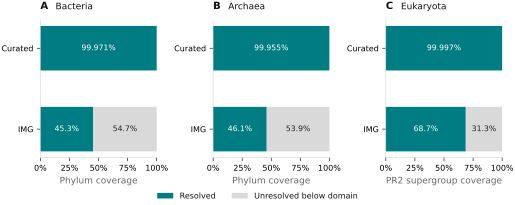

In [9]:
resolution_colors = {"resolved": "#007C83", "unresolved": "#D9D9D9"}
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.65), sharex=True, constrained_layout=True)

for panel, domain, ax in zip(("A", "B", "C"), domain_order, axes, strict=True):
    subset = (
        resolution.loc[resolution["domain"].eq(domain)]
        .set_index("profile")
        .reindex(profile_order)
    )
    resolved_percent = subset["resolved_sequences"].to_numpy() / subset["total_sequences"].to_numpy() * 100
    unresolved_percent = 100 - resolved_percent
    positions = np.arange(len(profile_order))
    ax.barh(positions, resolved_percent, color=resolution_colors["resolved"], height=0.55, label="Resolved")
    ax.barh(
        positions,
        unresolved_percent,
        left=resolved_percent,
        color=resolution_colors["unresolved"],
        height=0.55,
        label="Unresolved below domain",
    )
    for row, (resolved_value, unresolved_value) in enumerate(
        zip(resolved_percent, unresolved_percent, strict=True)
    ):
        if resolved_value >= 10:
            ax.text(resolved_value / 2, row, coverage_label(resolved_value), ha="center", va="center", fontsize=7.7, color="white")
        if unresolved_value >= 10:
            ax.text(resolved_value + unresolved_value / 2, row, f"{unresolved_value:.1f}%", ha="center", va="center", fontsize=7.7, color="#222222")
    ax.set_yticks(positions, [profile_labels[item] for item in profile_order])
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    finalize_axes(ax, xlabel=f"{rank_labels[subset['target_rank'].iloc[0]]} coverage")
    ax.text(0.0, 1.06, panel, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom")
    ax.text(0.13, 1.06, domain, transform=ax.transAxes, fontsize=9, va="bottom")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.10), ncol=2, frameon=False)
save_figure(fig, "database-taxonomy-resolution")
plt.close(fig)
display(
    SVG(filename=FIGURES / "database-taxonomy-resolution.svg"),
    metadata={"alt": "Three panels compare phylum or PR2-supergroup resolution between the curated and IMG profiles for Bacteria, Archaea, and Eukaryota."},
)


**Figure 1 | Target-rank resolution.** A, bacterial phylum coverage. B, archaeal phylum coverage. C, eukaryotic PR2-supergroup coverage. Percentages are calculated within each domain. Domain-only IMG assignments lower target-rank coverage within each assigned domain.


### Reported lineages

The reported lineage counts are identical in both profiles because the IMG additions do not contribute phylum- or supergroup-level assignments. The table lists the five most abundant lineages for each domain. The figure keeps the PR2 placeholder `Eukaryota_X` separate from named eukaryotic supergroups.


In [10]:
curated_lineages = lineages.loc[lineages["profile"].eq("curated")].copy()
img_lineages = lineages.loc[lineages["profile"].eq("img")].copy()
lineage_comparison = curated_lineages.merge(
    img_lineages,
    on=["domain", "target_rank", "lineage"],
    suffixes=("_curated", "_img"),
    how="outer",
    validate="one_to_one",
).fillna(0)
assert (lineage_comparison["count_curated"] == lineage_comparison["count_img"]).all()

resolved_totals = (
    resolution.loc[resolution["profile"].eq("curated")]
    .set_index("domain")["resolved_sequences"]
)
curated_lineages["share"] = (
    curated_lineages["count"] / curated_lineages["domain"].map(resolved_totals) * 100
)
top_lineage_table = (
    curated_lineages.sort_values(["domain", "count", "lineage"], ascending=[True, False, True])
    .groupby("domain", observed=True, sort=False)
    .head(5)
    .copy()
)
top_lineage_table["Domain"] = top_lineage_table["domain"]
top_lineage_table["Reported rank"] = top_lineage_table["target_rank"].map(rank_labels)
top_lineage_table["Named lineage"] = top_lineage_table["lineage"]
top_lineage_table["Sequence assignments"] = top_lineage_table["count"]
top_lineage_table["Share of resolved assignments (%)"] = top_lineage_table["share"]
top_lineage_table["Domain"] = pd.Categorical(
    top_lineage_table["Domain"], categories=domain_order, ordered=True
)
top_lineage_table = top_lineage_table.sort_values(
    ["Domain", "Sequence assignments"], ascending=[True, False]
)[
    [
        "Domain", "Reported rank", "Named lineage", "Sequence assignments",
        "Share of resolved assignments (%)",
    ]
]
show_table(
    top_lineage_table,
    {
        "Sequence assignments": "{:,.0f}",
        "Share of resolved assignments (%)": "{:.1f}",
    },
    "top-lineages",
)


Domain,Reported rank,Named lineage,Sequence assignments,Share of resolved assignments (%)
Bacteria,Phylum,Pseudomonadota,"112,577",29.0
Bacteria,Phylum,Bacillota,"105,912",27.2
Bacteria,Phylum,Bacteroidota,"42,902",11.0
Bacteria,Phylum,Actinomycetota,"36,964",9.5
Bacteria,Phylum,Acidobacteriota,"11,556",3.0
Archaea,Phylum,Thermoproteota,"7,610",37.7
Archaea,Phylum,Halobacteriota,"5,345",26.5
Archaea,Phylum,Thermoplasmatota,"2,895",14.4
Archaea,Phylum,Methanobacteriota,"2,001",9.9
Archaea,Phylum,Asgardarchaeota,670,3.3


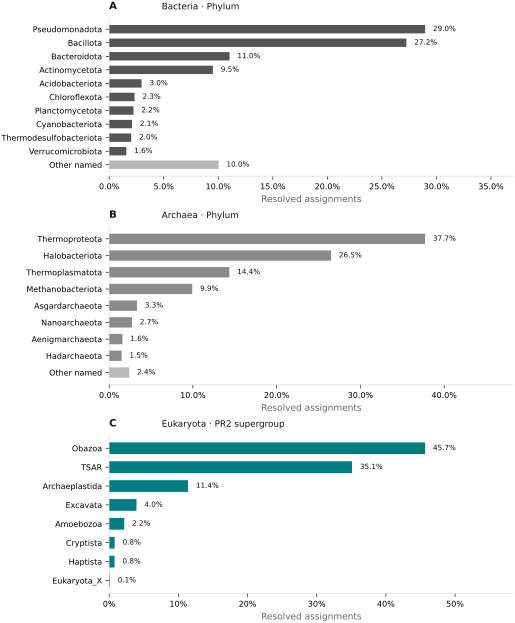

In [11]:
top_n = {"Bacteria": 10, "Archaea": 8, "Eukaryota": 7}
lineage_colors = {"Bacteria": "#555555", "Archaea": "#8A8A8A", "Eukaryota": "#007C83"}
fig, axes = plt.subplots(3, 1, figsize=(7.2, 8.7), constrained_layout=True)

for panel, domain, ax in zip(("A", "B", "C"), domain_order, axes, strict=True):
    subset = (
        curated_lineages.loc[curated_lineages["domain"].eq(domain)]
        .sort_values(["count", "lineage"], ascending=[False, True])
        .copy()
    )
    if domain == "Eukaryota":
        placeholder = subset.loc[subset["lineage"].eq("Eukaryota_X")].copy()
        assert len(placeholder) == 1
        selected = subset.loc[~subset["lineage"].eq("Eukaryota_X")].head(top_n[domain]).copy()
        selected = pd.concat([selected, placeholder], ignore_index=True)
        other_count = 0
    else:
        selected = subset.head(top_n[domain]).copy()
        other_count = int(subset.iloc[top_n[domain]:]["count"].sum())
    if other_count:
        selected = pd.concat(
            [
                selected,
                pd.DataFrame(
                    [{
                        "domain": domain,
                        "target_rank": subset["target_rank"].iloc[0],
                        "lineage": "Other named",
                        "count": other_count,
                    }]
                ),
            ],
            ignore_index=True,
        )
    selected["percent"] = selected["count"] / resolved_totals[domain] * 100
    selected = selected.iloc[::-1]
    bars = ax.barh(
        np.arange(len(selected)),
        selected["percent"],
        color=["#B8B8B8" if label == "Other named" else lineage_colors[domain] for label in selected["lineage"]],
        height=0.62,
    )
    ax.set_yticks(np.arange(len(selected)), selected["lineage"])
    maximum = float(selected["percent"].max())
    ax.set_xlim(0, maximum * 1.28)
    for bar, value in zip(bars, selected["percent"], strict=True):
        ax.text(
            value + maximum * 0.025,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.1f}%",
            va="center",
            fontsize=7.2,
        )
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    finalize_axes(ax, xlabel="Resolved assignments")
    ax.text(0.0, 1.04, panel, transform=ax.transAxes, fontsize=10, fontweight="bold", va="bottom")
    ax.text(
        0.13,
        1.04,
        f"{domain} · {rank_labels[subset['target_rank'].iloc[0]]}",
        transform=ax.transAxes,
        fontsize=8.8,
        va="bottom",
    )

save_figure(fig, "database-taxonomy-lineages")
plt.close(fig)
display(
    SVG(filename=FIGURES / "database-taxonomy-lineages.svg"),
    metadata={"alt": "Three horizontal bar panels report the most abundant bacterial phyla, archaeal phyla, and eukaryotic PR2 supergroups among resolved reference assignments."},
)


**Figure 2 | Reported lineage distribution.** A, bacterial phyla. B, archaeal phyla. C, eukaryotic PR2 supergroups. Percentages use sequences resolved to the reported rank as the denominator. Less abundant bacterial and archaeal lineages are combined as “Other named.” The eukaryotic panel shows the seven most abundant named supergroups and the separate PR2 placeholder `Eukaryota_X`. PR2 organellar labels are counted with the parent supergroup.


## IMG sampling coordinates

The released IMG metadata table retains the IMG Taxon OID and latitude/longitude when both coordinates are available. Project names, contact details, and free-text fields are excluded. The source records contain 32,521 Taxon OIDs; 30,349 have complete coordinates and 2,172 do not. One Taxon OID has no row in the location table and is retained in the derived table with null coordinates.


In [12]:
coordinate_details = provenance["profiles"]["img"]["coordinate_coverage"]
coordinate_table = pd.DataFrame(
    [
        {"Measure": "IMG taxa represented by source records", "Count": coordinate_details["taxa"], "Coverage": 100.0},
        {
            "Measure": "IMG taxa present in the original location table",
            "Count": coordinate_details["location_table_rows"],
            "Coverage": coordinate_details["location_table_rows"] / coordinate_details["taxa"] * 100,
        },
        {
            "Measure": "IMG taxa with latitude and longitude",
            "Count": coordinate_details["located_taxa"],
            "Coverage": coordinate_details["located_taxa"] / coordinate_details["taxa"] * 100,
        },
        {
            "Measure": "IMG taxa without a complete coordinate pair",
            "Count": coordinate_details["taxa"] - coordinate_details["located_taxa"],
            "Coverage": (coordinate_details["taxa"] - coordinate_details["located_taxa"]) / coordinate_details["taxa"] * 100,
        },
        {
            "Measure": "IMG source records linked to a complete coordinate pair",
            "Count": coordinate_details["located_source_records"],
            "Coverage": coordinate_details["located_source_records"] / coordinate_details["source_records"] * 100,
        },
        {"Measure": "Distinct coordinate pairs", "Count": coordinate_details["sites"], "Coverage": np.nan},
    ]
)
show_table(
    coordinate_table,
    {"Count": "{:,.0f}", "Coverage": lambda value: "" if pd.isna(value) else coverage_label(value)},
    "coordinate-coverage",
)

site_groups = pd.DataFrame(coordinate_details["marker_groups"]).rename(
    columns={"marker_group": "Marker records at coordinate", "sites": "Coordinate pairs"}
)
site_groups["Marker records at coordinate"] = site_groups["Marker records at coordinate"].map(site_marker_labels)
show_table(site_groups, {"Coordinate pairs": "{:,.0f}"}, "coordinate-marker-groups")


Measure,Count,Coverage
IMG taxa represented by source records,"32,521",100.0%
IMG taxa present in the original location table,"32,520",99.997%
IMG taxa with latitude and longitude,"30,349",93.3%
IMG taxa without a complete coordinate pair,"2,172",6.7%
IMG source records linked to a complete coordinate pair,"931,810",93.4%
Distinct coordinate pairs,"4,856",


Marker records at coordinate,Coordinate pairs
16S rRNA genes and 18S rRNA genes,"3,445"
16S rRNA genes only,"1,336"
18S rRNA genes only,75


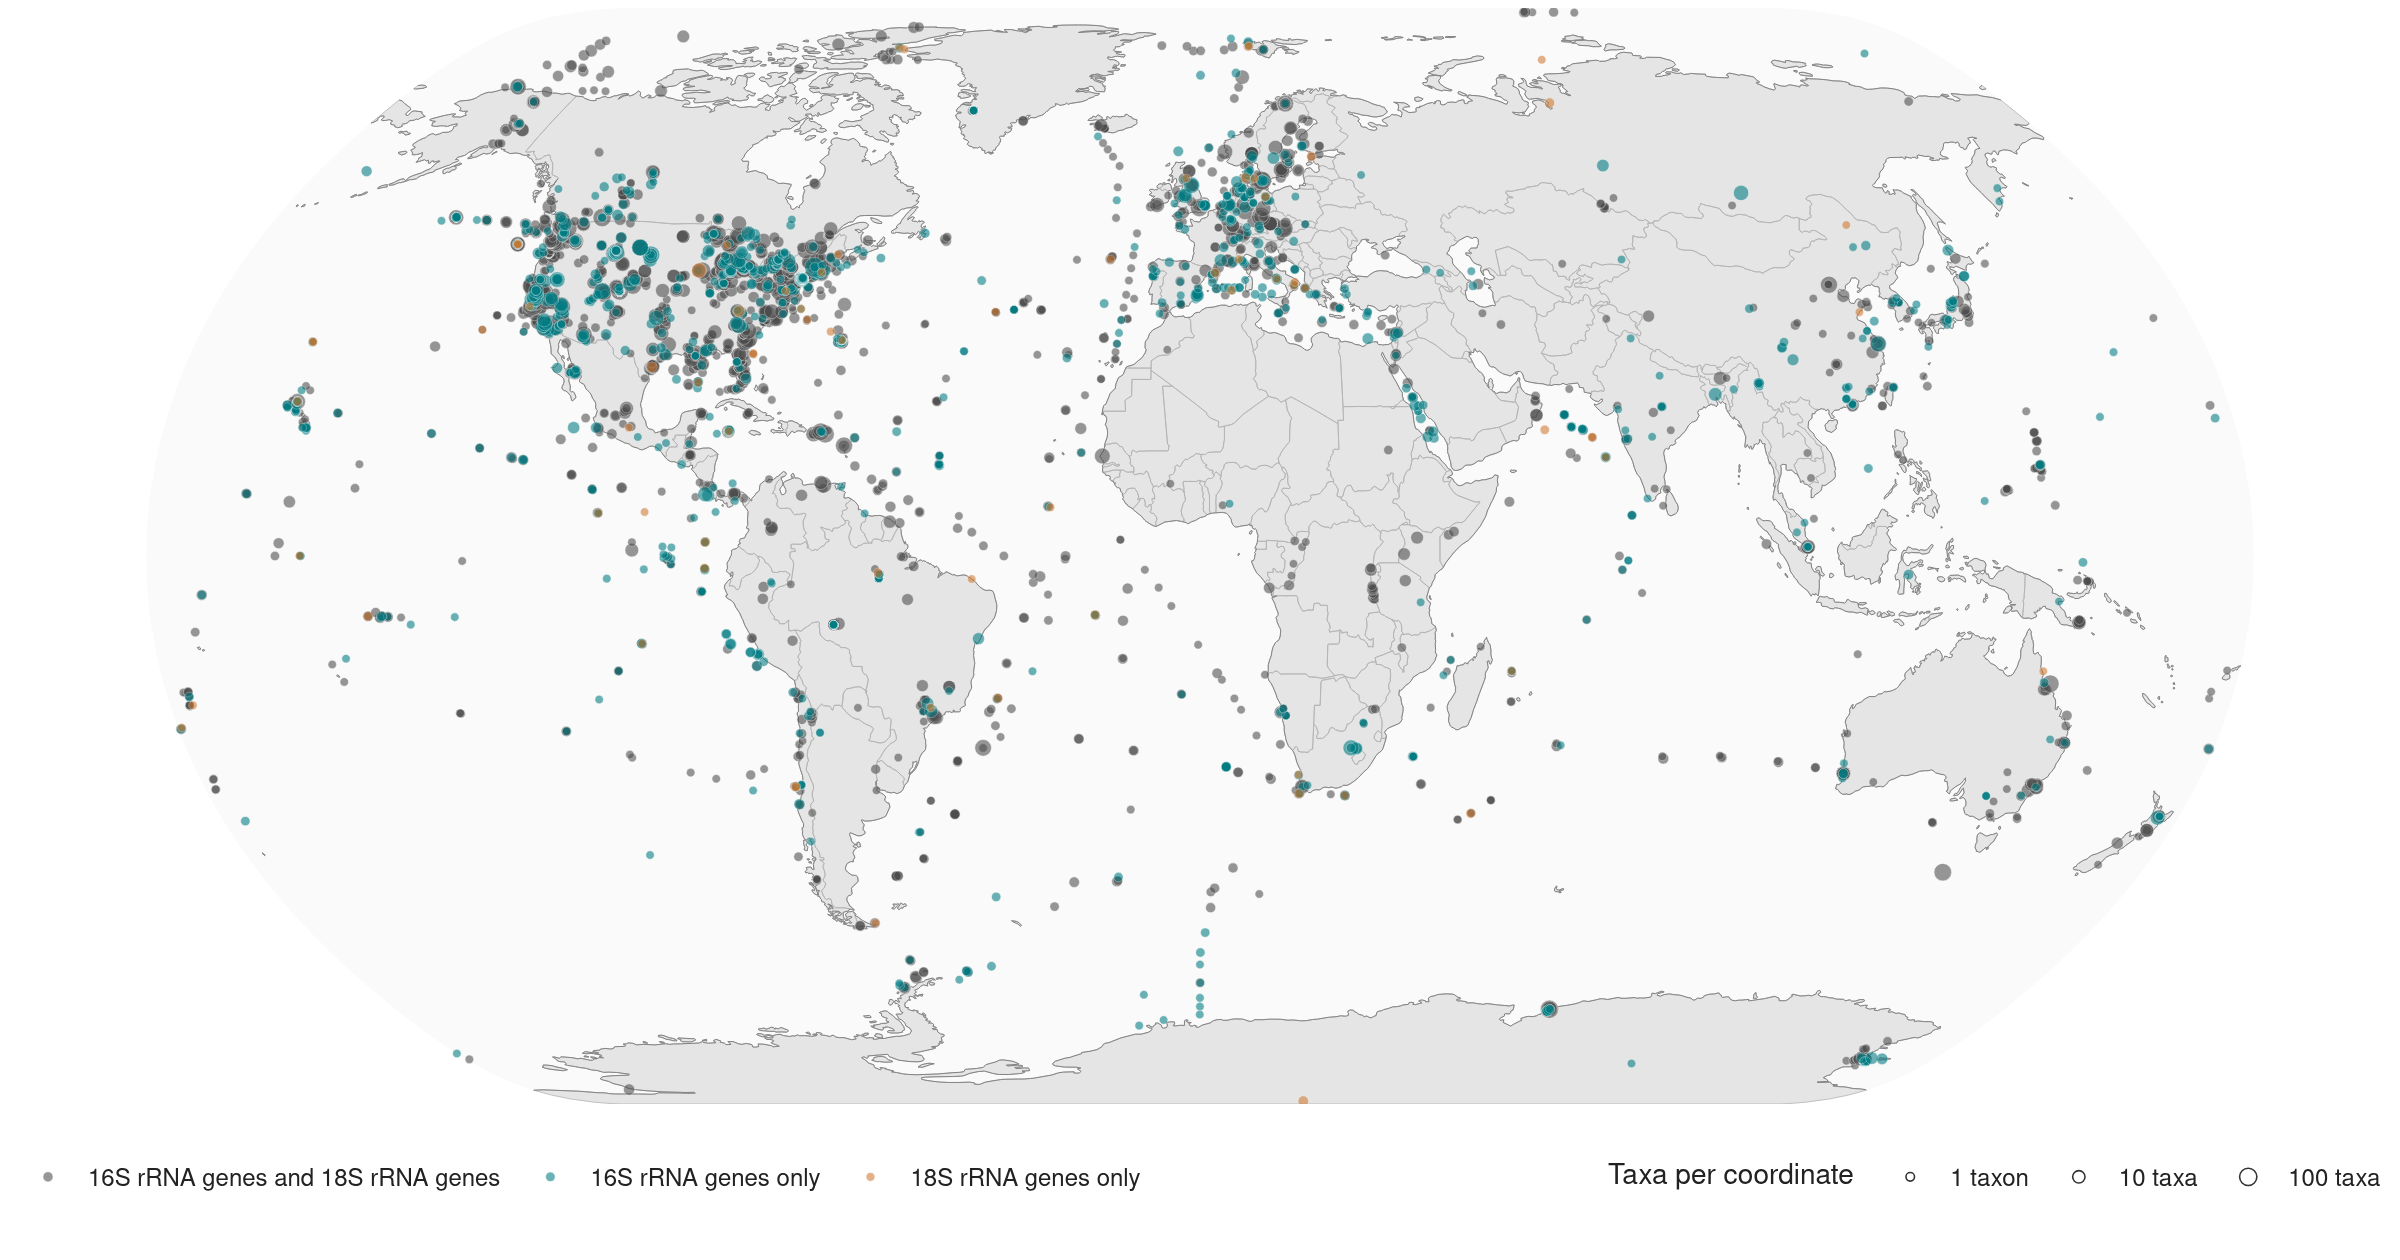

In [13]:
marker_order = ["16S + 18S", "16S only", "18S only"]
marker_colors = {"16S + 18S": "#4D4D4D", "16S only": "#007C83", "18S only": "#D07A32"}
assert set(sites["marker_group"]) == set(marker_order)
pio.json.config.default_engine = "json"

map_figure = go.Figure()
maximum_taxa = float(sites["taxa"].max())


def map_marker_size(values):
    values = np.asarray(values, dtype=float)
    sizes = 3.5 + 7.5 * np.log1p(values) / np.log1p(maximum_taxa)
    return np.round(sizes, decimals=6)


for marker_group in marker_order:
    subset = sites.loc[sites["marker_group"].eq(marker_group)].copy()
    extra_taxa = np.maximum(subset["taxa"].to_numpy() - 5, 0)
    marker_size = map_marker_size(subset["taxa"].to_numpy())
    customdata = np.column_stack(
        [
            subset["taxa"].to_numpy(),
            subset["records_16s"].to_numpy(),
            subset["records_18s"].to_numpy(),
            subset["taxon_oid_preview"].to_numpy(),
            extra_taxa,
        ]
    )
    map_figure.add_trace(
        go.Scattergeo(
            lon=subset["longitude"],
            lat=subset["latitude"],
            mode="markers",
            name=site_marker_labels[marker_group],
            customdata=customdata,
            marker={
                "size": marker_size,
                "color": marker_colors[marker_group],
                "opacity": 0.58,
                "line": {"width": 0.25, "color": "#FFFFFF"},
            },
            hovertemplate=(
                "<b>%{lat:.4f}, %{lon:.4f}</b><br>"
                "IMG taxa: %{customdata[0]:,.0f}<br>"
                "16S rRNA gene source records: %{customdata[1]:,.0f}<br>"
                "18S rRNA gene source records: %{customdata[2]:,.0f}<br>"
                "Taxon OID preview: %{customdata[3]}<br>"
                "Additional taxa at coordinate: %{customdata[4]:,.0f}"
                "<extra>%{fullData.name}</extra>"
            ),
        )
    )

size_legend_values = [value for value in (1, 10, 100, 1000) if value <= maximum_taxa]
for value, size in zip(size_legend_values, map_marker_size(size_legend_values), strict=True):
    map_figure.add_trace(
        go.Scattergeo(
            lon=[None],
            lat=[None],
            mode="markers",
            name=f"{value:,} {'taxon' if value == 1 else 'taxa'}",
            marker={
                "size": float(size),
                "color": "#FFFFFF",
                "line": {"width": 0.8, "color": "#333333"},
            },
            hoverinfo="skip",
            showlegend=True,
            legend="legend2",
        )
    )

map_figure.update_geos(
    projection_type="natural earth",
    showframe=False,
    showland=True,
    landcolor="#E5E5E5",
    showocean=True,
    oceancolor="#FAFAFA",
    showlakes=False,
    showcountries=True,
    countrycolor="#B3B3B3",
    countrywidth=0.4,
    showcoastlines=True,
    coastlinecolor="#858585",
    coastlinewidth=0.5,
    lataxis={"range": [-90, 90], "showgrid": False},
    lonaxis={"range": [-180, 180], "showgrid": False},
    bgcolor="#FFFFFF",
)
map_figure.update_layout(
    width=980,
    height=520,
    margin={"l": 4, "r": 4, "t": 4, "b": 78},
    paper_bgcolor="#FFFFFF",
    plot_bgcolor="#FFFFFF",
    font={"family": "Arial, Helvetica, sans-serif", "size": 12, "color": "#222222"},
    legend={"orientation": "h", "x": 0.0, "xanchor": "left", "y": -0.04, "yanchor": "top"},
    legend2={
        "title": {"text": "Taxa per coordinate"},
        "orientation": "h",
        "x": 1.0,
        "xanchor": "right",
        "y": -0.04,
        "yanchor": "top",
    },
)
map_config = {"displaylogo": False, "scrollZoom": True, "responsive": True}
map_figure_spec = json.dumps(
    json.loads(
        pio.to_json(
            map_figure, validate=True, pretty=False, remove_uids=True, engine="json"
        )
    ),
    ensure_ascii=True,
    allow_nan=False,
    sort_keys=True,
    separators=(",", ":"),
)
map_figure_sha256 = hashlib.sha256(map_figure_spec.encode("utf-8")).hexdigest()
map_path = FIGURES / "img-ssu-locations.html"
map_png = FIGURES / "img-ssu-locations.png"
map_export_width = 1200
map_export_height = 630
map_png_scale = 2
visualization_schema_version = 4
map_render_contract = {
    "figure_serialization": "plotly-json-sorted-v1",
    "figure_sha256": map_figure_sha256,
    "html_path": str(map_path.relative_to(ROOT)),
    "width": map_export_width,
    "height": map_export_height,
    "png_scale": map_png_scale,
}
render_static_map_value = os.environ.get("SSUEXTRACT_RENDER_STATIC_MAP", "1")
if render_static_map_value not in {"0", "1"}:
    raise ValueError("SSUEXTRACT_RENDER_STATIC_MAP must be 0 or 1")
render_static_map = render_static_map_value == "1"
visualization_path = DATA / "database_composition_visuals.json"
previous_visualization_manifest = None
if visualization_path.is_file():
    previous_visualization_manifest = json.loads(
        visualization_path.read_text(encoding="utf-8")
    )

if render_static_map:
    pio.write_html(
        map_figure,
        file=str(map_path),
        include_plotlyjs=True,
        full_html=True,
        config=map_config,
        div_id="ssuextract-img-ssu-locations",
        auto_open=False,
    )
    map_html = map_path.read_text(encoding="utf-8")
    map_path.write_text(
        "\n".join(line.rstrip() for line in map_html.splitlines()) + "\n",
        encoding="utf-8",
    )
    map_png_temporary = FIGURES / ".img-ssu-locations.png.tmp"
    pio.write_image(
        map_figure,
        file=str(map_png_temporary),
        format="png",
        width=map_export_width,
        height=map_export_height,
        scale=map_png_scale,
    )
    map_visual_changed = (
        not map_png.is_file()
        or file_sha256(map_png_temporary) != file_sha256(map_png)
    )
    if map_visual_changed:
        os.replace(map_png_temporary, map_png)
    else:
        map_png_temporary.unlink()

else:
    missing_map_files = [
        path for path in (map_path, map_png) if not path.is_file()
    ]
    if missing_map_files:
        raise FileNotFoundError(
            f"map artifacts are missing: {', '.join(map(str, missing_map_files))}"
        )
    if previous_visualization_manifest is None:
        raise FileNotFoundError(f"visualization manifest is missing: {visualization_path}")
    previous_map_render = previous_visualization_manifest.get("browser_render")
    if (
        previous_visualization_manifest.get("schema_version")
        != visualization_schema_version
        or not isinstance(previous_map_render, dict)
        or any(
            previous_map_render.get(key) != value
            for key, value in map_render_contract.items()
        )
    ):
        raise RuntimeError(
            "the visualization manifest lacks the current browser-render contract; "
            "regenerate it with SSUEXTRACT_RENDER_STATIC_MAP=1"
        )
    previous_output_hashes = {
        output["path"]: output.get("sha256")
        for output in previous_visualization_manifest.get("outputs", [])
        if isinstance(output, dict) and isinstance(output.get("path"), str)
    }
    for map_artifact_path in (map_path, map_png):
        relative_map_artifact_path = str(map_artifact_path.relative_to(ROOT))
        if previous_output_hashes.get(relative_map_artifact_path) != file_sha256(
            map_artifact_path
        ):
            raise RuntimeError(
                f"{relative_map_artifact_path} does not match the visualization manifest; "
                "regenerate map artifacts with SSUEXTRACT_RENDER_STATIC_MAP=1"
            )

map_path.chmod(0o644)
map_png.chmod(0o644)

display(
    Image(
        filename=map_png,
        embed=True,
        width=1100,
        alt="Natural Earth map of available IMG sampling coordinates on a simplified grayscale basemap, colored by whether the coordinate contributes 16S rRNA gene records, 18S rRNA gene records, or both.",
    )
)

map_fragment = map_figure.to_html(
    include_plotlyjs=True,
    full_html=False,
    config=map_config,
    div_id="ssuextract-img-ssu-locations-notebook",
)
display(HTML(map_fragment))


**Figure 3 | IMG sampling coordinates.** The static map and the interactive Plotly map below it show 30,349 of 32,521 IMG taxa aggregated into 4,856 exact coordinate pairs. Point diameter scales logarithmically with the number of taxa at a coordinate. Color reports whether the coordinate contributes 16S rRNA gene records, 18S rRNA gene records, or both. Hover labels report coordinates, source-record counts, and up to five IMG Taxon OIDs. The map reports the coordinates available in the released metadata; repeated taxa and studies at one coordinate mean that point density is not a measure of environmental abundance or geographic sampling effort.


In [14]:
visual_paths = [
    FIGURES / "database-taxonomy-resolution.svg",
    FIGURES / "database-taxonomy-lineages.svg",
    map_png,
    map_path,
]
visualization_manifest = {
    "schema_version": visualization_schema_version,
    "source": {
        "path": str(provenance_path.relative_to(ROOT)),
        "bytes": provenance_path.stat().st_size,
        "sha256": file_sha256(provenance_path),
    },
    "browser_render": map_render_contract,
    "outputs": [
        {
            "path": str(path.relative_to(ROOT)),
            "bytes": path.stat().st_size,
            "sha256": file_sha256(path),
        }
        for path in visual_paths
    ],
}
temporary_visualization_path = DATA / ".database_composition_visuals.json.tmp"
temporary_visualization_path.write_text(
    json.dumps(visualization_manifest, indent=2, sort_keys=True) + "\n",
    encoding="utf-8",
)
os.replace(temporary_visualization_path, visualization_path)
visualization_path.chmod(0o644)
